# 09 · Empirical laws across all experiments

Four relations that fit every experiment so far (centralized, main sweep, path, alignment, server step). Values are ·η/2 (1 = classical edge 2/η) unless stated.

| | Relation | Free constants |
|---|---|---|
| L1 | per-step overshoot is universal: `c_eff = (1 + g^{1/K})/2 = c ≈ 1.08` | c |
| L1a | IID edge (any K, η_s): smallest `x = ηλ` with `\|1 − η_s(1 − (1 − x)^K)\| = (2c − 1)^K` | none beyond c |
| L2 | non-IID: `λ_global = λ̄ − M(α)`, with `λ̄ = Σ pᵢ λᵢ ≈ c + A(α)/K` and `M` set by α, not K | A, M per α |
| L3 | sharpest client: `λ_max ≈ c_max + B(α)/K` | c_max, B per α |
| L4 | real (path) round: `c_path − 1 ≈ (c − 1)` for odd K, `≈ 0.3 (c − 1)` for even K | none (descriptive) |

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
AL = {np.inf: "α=∞ (IID)", 1.0: "α=1", 0.1: "α=0.1"}
COL = {np.inf: "C0", 1.0: "C2", 0.1: "C3"}
def edge_line(ax, y=1.0): ax.axhline(y, color="k", lw=0.8)

main = obs.load_runs("fedavg_main"); mtraj = obs.load_traj("fedavg_main")
srv = obs.load_runs("fedavg_server_lr")
try:
    cen = obs.load_runs("centralized"); c_gd = dict(zip(cen.lr, cen.eq_sharp_norm))
except FileNotFoundError:
    c_gd = {0.02: 1.068, 0.04: 1.086, 0.08: 1.097}; print("centralized not found; using the measured values", c_gd)
print("centralized GD, sharpness·η/2:", {k: round(v, 3) for k, v in c_gd.items()})

centralized GD, sharpness·η/2: {0.02: 1.066, 0.04: 1.088, 0.08: 1.097}


## L1 · The per-step overshoot is universal

For every FedAvg run, the frozen round map's growth per round `g`, taken per local step, gives `c_eff = (1 + g^{1/K})/2`. For K = 1 this is plain GD's sharpness·η/2. The claim: `c_eff` is the same constant for every α, K, η and η_s, and equals GD's EoS overshoot.

Main sweep: c_eff measured from the frozen round map. Server-step runs (round map off): c_eff from the identical-client map at the measured λ, `g = |1 − η_s(1 − (1 − ηλ)^K)|`.

main sweep: c = 1.077 ± 0.010 over 55 runs;  GD: 1.083 (1.066–1.097)
server step: 1.056 ± 0.019 over 9 runs


alpha,0.1,1.0,inf
local_steps,,,
1,1.077,1.077,1.078
2,1.059,1.071,1.078
5,1.076,1.075,1.078
10,1.076,1.084,1.079
20,1.080,1.089,1.078


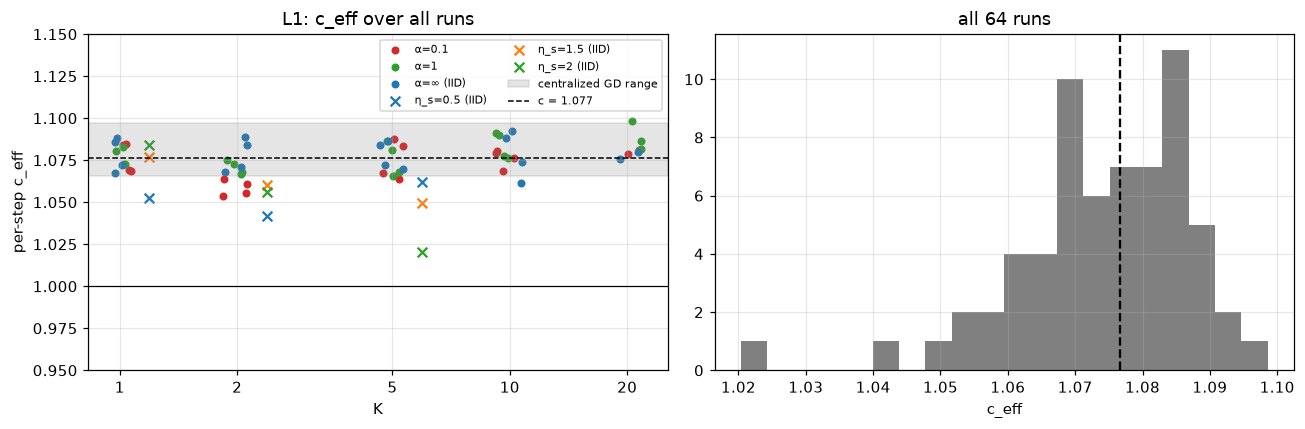

In [2]:
def toy_ceff(x, K, s):            # x = ηλ
    g = np.abs(1 - s * (1 - (1 - x) ** K))
    return (1 + g ** (1 / K)) / 2
m1 = main.dropna(subset=["eq_ceff_frozen"])[["alpha", "local_steps", "lr", "seed", "eq_ceff_frozen"]].rename(columns={"eq_ceff_frozen": "c_eff"})
m1["source"], m1["server_lr"] = "main (measured map)", 1.0
s1 = srv[["alpha", "local_steps", "lr", "seed", "server_lr"]].copy()
s1["c_eff"] = toy_ceff(2 * srv.eq_sharp_norm, srv.local_steps, srv.server_lr); s1["source"] = "server step (toy map at measured λ)"
L1 = pd.concat([m1, s1], ignore_index=True)
c = m1.c_eff.mean()
print(f"main sweep: c = {c:.3f} ± {m1.c_eff.std():.3f} over {len(m1)} runs;  GD: {np.mean(list(c_gd.values())):.3f} ({min(c_gd.values()):.3f}–{max(c_gd.values()):.3f})")
print(f"server step: {s1.c_eff.mean():.3f} ± {s1.c_eff.std():.3f} over {len(s1)} runs")
display(m1.groupby(["alpha", "local_steps"]).c_eff.mean().unstack("alpha").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]; rng = np.random.default_rng(0)
for a, g in m1.groupby("alpha"):
    ax.scatter(np.log2(g.local_steps) + rng.uniform(-.12, .12, len(g)), g.c_eff, c=COL[a], s=18, label=AL[a])
for s, g in s1.groupby("server_lr"):
    ax.scatter(np.log2(g.local_steps) + 0.25, g.c_eff, marker="x", s=40, label=f"η_s={s:g} (IID)")
ax.axhspan(min(c_gd.values()), max(c_gd.values()), color="grey", alpha=0.2, label="centralized GD range")
ax.axhline(c, color="k", ls="--", lw=1, label=f"c = {c:.3f}"); edge_line(ax)
ax.set_xticks(np.log2([1, 2, 5, 10, 20])); ax.set_xticklabels([1, 2, 5, 10, 20]); ax.set_xlabel("K"); ax.set_ylabel("per-step c_eff")
ax.set_ylim(0.95, 1.15); ax.legend(fontsize=7, ncol=2); ax.set_title("L1: c_eff over all runs")
axes[1].hist(L1.c_eff, bins=20, color="grey"); axes[1].axvline(c, color="k", ls="--"); axes[1].set_xlabel("c_eff"); axes[1].set_title(f"all {len(L1)} runs")
plt.tight_layout(); plt.show()

### L1a · Closed-form IID edge

With identical clients the round map has eigenvalues `η_s(1 − (1 − ηλ)^K)`. Setting its per-step growth to the universal `2c − 1` gives the edge as the smallest `x = ηλ` with `|1 − η_s(1 − (1 − x)^K)| = (2c − 1)^K`. Special cases: η_s = 1 → `c` for every K; K = 1 → `c/η_s`; even K → `(1 + (1 + ((2c−1)^K − 1)/η_s)^{1/K})/2`.

Below: one constant `c` (from the main sweep) against the classical toy edge (c = 1), for every IID run.

29 IID runs.  mean |error|: law with c = 1.077: 1.9%   toy edge (c = 1): 7.2%
largest errors (law):


,local_steps,server_lr,lr,seed,eq_sharp_norm,pred_c,pred_toy,err
28,5,2.0,0.02,0,0.822,0.939,0.500,14.207
23,2,0.5,0.02,0,1.081,1.144,1.000,5.832
27,5,1.5,0.02,0,0.970,1.003,0.901,3.317
20,1,0.5,0.02,0,2.105,2.153,2.000,2.307


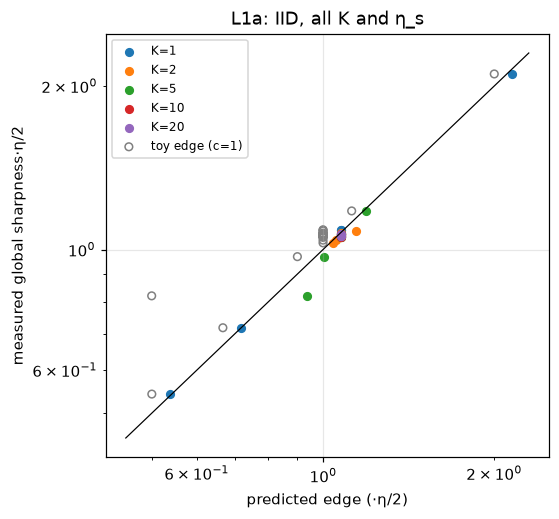

In [3]:
def edge(K, s, c):
    x = np.linspace(1e-4, 6, 600001)
    hit = np.abs(1 - s * (1 - (1 - x) ** K)) >= (2 * c - 1) ** K
    return x[np.argmax(hit)] / 2
iid = pd.concat([main[main.alpha == np.inf], srv], ignore_index=True)[["local_steps", "server_lr", "lr", "seed", "eq_sharp_norm"]]
iid["pred_c"] = [edge(k, s, c) for k, s in zip(iid.local_steps, iid.server_lr)]
iid["pred_toy"] = [edge(k, s, 1.0) for k, s in zip(iid.local_steps, iid.server_lr)]
err = lambda p: (100 * (iid[p] - iid.eq_sharp_norm).abs() / iid.eq_sharp_norm)
print(f"{len(iid)} IID runs.  mean |error|: law with c = {c:.3f}: {err('pred_c').mean():.1f}%   toy edge (c = 1): {err('pred_toy').mean():.1f}%")
print("largest errors (law):"); display(iid.assign(err=err("pred_c")).sort_values("err", ascending=False).head(4))
fig, ax = plt.subplots(figsize=(5.2, 5))
for K, g in iid.groupby("local_steps"):
    ax.scatter(g.pred_c, g.eq_sharp_norm, label=f"K={K}", s=25)
ax.scatter(iid.pred_toy, iid.eq_sharp_norm, facecolors="none", edgecolors="grey", s=25, label="toy edge (c=1)")
lim = [0.45, 2.3]; ax.plot(lim, lim, "k-", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("predicted edge (·η/2)"); ax.set_ylabel("measured global sharpness·η/2"); ax.legend(fontsize=8); ax.set_title("L1a: IID, all K and η_s"); plt.show()

## L2 · Non-IID: global = client average − misalignment

Exact identity: `λ_global = Σ pᵢ v_gᵀHᵢv_g = λ̄ − M`, with `λ̄ = Σ pᵢ λᵢ` (pᵢ = data share) and misalignment `M ≥ 0`. In the main sweep I compute `λ̄` from the per-client top eigenvalues and infer `M = λ̄ − λ_global` for every run. The alignment runs measure M directly and serve as a check.

In [4]:
sp = obs.load_splits("fedavg_main")
def pvec(a):
    k = [k for k in sp if k.startswith(f"alpha={'inf' if a == np.inf else float(a)} ")][0]
    s = np.array(sp[k]["sizes"], float); return s / s.sum()
rows = []
for run, t in mtraj.groupby("run"):
    t = t[t.steps >= 0.7 * t.steps.max()]; a, h = t.alpha.iloc[0], t.lr.iloc[0] / 2
    C = np.vstack([np.asarray(x) for x in t.client_sharp.dropna()]); p = pvec(a)
    rows.append({"run": run, "alpha": a, "K": int(t.local_steps.iloc[0]), "lr": t.lr.iloc[0],
                 "global": t.sharpness.median() * h, "λ̄": np.median(C @ p) * h, "max client": np.median(C.max(1)) * h})
D = pd.DataFrame(rows); D["M"] = D["λ̄"] - D["global"]
display(D.groupby(["alpha", "K"])[["global", "λ̄", "M", "max client"]].mean().round(3).unstack("alpha"))

al = obs.load_alignment("fedavg_align")
chk = pd.DataFrame([{"run": r, "M (alignment, exact)": a["misalignment_cost"] * a["lr"] / 2, "λ̄ (alignment)": a["weyl_sum"] * a["lr"] / 2} for r, a in al.items()])
print("alignment runs (5k steps, final point) for comparison:"); display(chk.round(3))

global                   λ̄                    M               max client              
alpha    0.1    1.0    inf    0.1    1.0    inf    0.1    1.0    inf        0.1    1.0    inf
K                                                                                            
1      1.077  1.077  1.079  1.264  1.121  1.107  0.187  0.044  0.028      1.459  1.238  1.150
2      1.006  1.051  1.063  1.138  1.090  1.092  0.132  0.038  0.029      1.235  1.188  1.129
5      0.993  1.053  1.062  1.117  1.090  1.089  0.124  0.037  0.027      1.183  1.166  1.120
10     0.978  1.049  1.061  1.092  1.088  1.086  0.113  0.040  0.025      1.148  1.151  1.112
20     0.978  1.047  1.062  1.088  1.085  1.087  0.109  0.038  0.025      1.144  1.149  1.110

alignment runs (5k steps, final point) for comparison:


,run,"M (alignment, exact)",λ̄ (alignment)
0,M10_a0.1_K10_lr0.02_slr1_s0,0.088,1.085
1,M10_a0.1_K5_lr0.02_slr1_s0,0.099,1.112
2,M10_ainf_K10_lr0.02_slr1_s0,0.020,1.095
3,M10_ainf_K5_lr0.02_slr1_s0,0.021,1.103


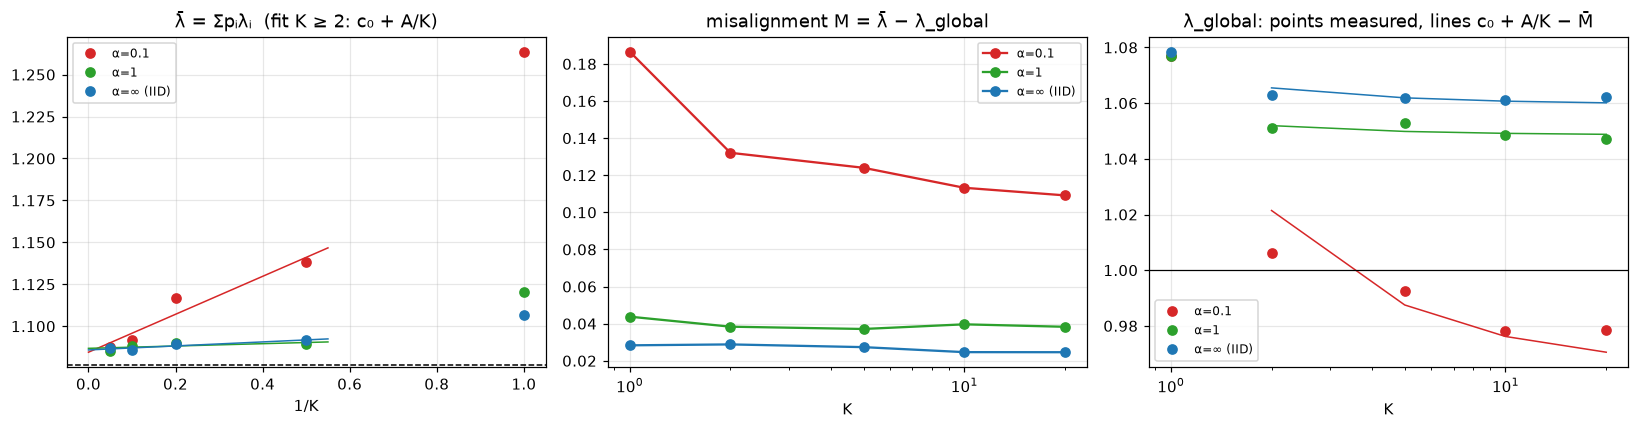

,c₀ (K→∞ client avg),A,M̄ (K ≥ 2)
α=0.1,1.085,0.113,0.120
α=1,1.087,0.007,0.038
α=∞ (IID),1.086,0.012,0.026


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fits = {}
for a, g in D.groupby("alpha"):
    s = g.groupby("K")[["λ̄", "M", "global"]].mean()
    gk = g[g.K >= 2]; A, c0 = np.polyfit(1 / gk.K, gk["λ̄"], 1); fits[a] = (c0, A, gk.M.mean())
    axes[0].plot(1 / s.index, s["λ̄"], "o", c=COL[a], label=AL[a]); xx = np.linspace(0, .55, 20); axes[0].plot(xx, c0 + A * xx, "-", c=COL[a], lw=1)
    axes[1].plot(s.index, s.M, "o-", c=COL[a], label=AL[a])
axes[0].axhline(c, color="k", ls="--", lw=1); axes[0].set_xlabel("1/K"); axes[0].set_title("λ̄ = Σpᵢλᵢ  (fit K ≥ 2: c₀ + A/K)"); axes[0].legend(fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xlabel("K"); axes[1].set_title("misalignment M = λ̄ − λ_global"); axes[1].legend(fontsize=8)
for a, (c0, A, Mb) in fits.items():
    g = D[D.alpha == a].groupby("K")["global"].mean(); kk = np.array([2, 5, 10, 20])
    axes[2].plot(g.index, g.values, "o", c=COL[a], label=AL[a]); axes[2].plot(kk, c0 + A / kk - Mb, "-", c=COL[a], lw=1)
edge_line(axes[2]); axes[2].set_xscale("log"); axes[2].set_xlabel("K"); axes[2].set_title("λ_global: points measured, lines c₀ + A/K − M̄"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
F = pd.DataFrame({AL[a]: {"c₀ (K→∞ client avg)": v[0], "A": v[1], "M̄ (K ≥ 2)": v[2]} for a, v in fits.items()}).T
display(F.round(3))

### What sets M: heterogeneity, not K

M is roughly flat in K for K ≥ 2 and grows with label skew. Skew per split: p-weighted mean total-variation (TV) and KL distance of each client's label mix from the global mix.

,TV,KL,mean,std
α=0.1,0.643,1.152,0.120,0.018
α=1,0.379,0.403,0.038,0.007
α=∞ (IID),0.053,0.008,0.026,0.005


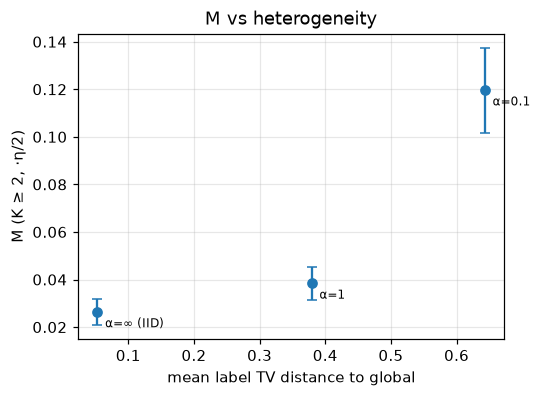

M by learning rate (α = 0.1, K ≥ 2): {0.02: 0.105, 0.04: 0.134}


In [6]:
H = {}
for k, v in sp.items():
    L = np.array(v["label_counts"], float); pi = L.sum(1) / L.sum(); P = L / L.sum(1, keepdims=True); G = L.sum(0) / L.sum()
    a = float(k.split()[0].split("=")[1]); H[a] = {"TV": (pi * 0.5 * np.abs(P - G).sum(1)).sum(),
                                                   "KL": (pi * (P * np.log(np.where(P > 0, P / G, 1))).sum(1)).sum()}
Hm = pd.DataFrame(H).T.join(D[D.K >= 2].groupby("alpha").M.agg(["mean", "std"]))
Hm.index = [AL[a] for a in Hm.index]; display(Hm.round(3))
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.errorbar(Hm.TV, Hm["mean"], yerr=Hm["std"], fmt="o", capsize=3)
for n, r in Hm.iterrows(): ax.annotate(n, (r.TV, r["mean"]), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.set_xlabel("mean label TV distance to global"); ax.set_ylabel("M (K ≥ 2, ·η/2)"); ax.set_title("M vs heterogeneity"); plt.show()
print("M by learning rate (α = 0.1, K ≥ 2):", D[(D.alpha == 0.1) & (D.K >= 2)].groupby("lr").M.mean().round(3).to_dict())

## L3 · Sharpest client: a 1/K approach

The sharpest client is above the edge by an amount that shrinks like 1/K. Heuristic: client i's own direction grows by about `wᵢ|1 − ηλᵢ|^K` per round, where wᵢ is its effective weight in the average. Requiring this to match the universal per-step growth gives `ηλᵢ/2 ≈ (1 + (2c − 1)·wᵢ^{−1/K})/2 ≈ c + (2c − 1)·ln(1/wᵢ)/(2K)`. So `λ_max ≈ c_max + B/K`, with `B` larger when clients are more distinct (smaller effective weight).

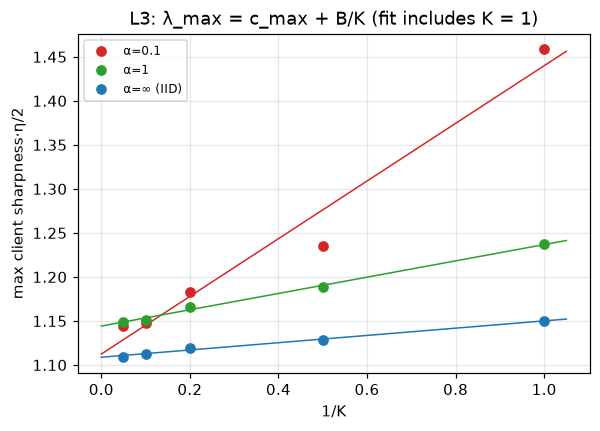

,c_max,B,R²,implied weight w
split,,,,
α=0.1,1.112,0.328,0.966,0.567
α=1,1.144,0.093,0.996,0.852
α=∞ (IID),1.109,0.041,0.991,0.931


In [7]:
fig, ax = plt.subplots(figsize=(6, 4)); rows = []
for a, g in D.groupby("alpha"):
    s = g.groupby("K")["max client"].mean(); kx = np.asarray(s.index, float); B, c0 = np.polyfit(1 / kx, s.values, 1)
    r2 = 1 - ((s.values - (c0 + B / kx)) ** 2).sum() / ((s.values - s.values.mean()) ** 2).sum()
    w = np.exp(-2 * B / (2 * c - 1)); rows.append({"split": AL[a], "c_max": c0, "B": B, "R²": r2, "implied weight w": w})
    ax.plot(1 / kx, s.values, "o", c=COL[a], label=AL[a]); xx = np.linspace(0, 1.05, 20); ax.plot(xx, c0 + B * xx, "-", c=COL[a], lw=1)
ax.set_xlabel("1/K"); ax.set_ylabel("max client sharpness·η/2"); ax.legend(fontsize=8); ax.set_title("L3: λ_max = c_max + B/K (fit includes K = 1)"); plt.show()
display(pd.DataFrame(rows).set_index("split").round(3))

## L4 · Real round vs frozen round: parity

Path-linearized round map (exact Jacobian of a real round) against the frozen one, at equilibrium. Descriptive only: 8 runs, 2–3 valid measurements each.

In [8]:
try:
    P = obs.load_runs("fedavg_path")
    Pt = P[["alpha", "local_steps", "eq_ceff_frozen", "eq_ceff_path"]].sort_values(["alpha", "local_steps"])
    Pt["parity"] = np.where(Pt.local_steps == 1, "K=1", np.where(Pt.local_steps % 2, "odd", "even"))
    Pt["(path−1)/(c−1)"] = (Pt.eq_ceff_path - 1) / (c - 1)
    display(Pt.round(3)); print(Pt.groupby("parity")["(path−1)/(c−1)"].mean().round(2).to_dict())
except FileNotFoundError as e:
    print(e)

,alpha,local_steps,eq_ceff_frozen,eq_ceff_path,parity,(path−1)/(c−1)
1,0.1,1,1.083,1.083,K=1,1.089
2,0.1,2,1.077,1.015,even,0.196
3,0.1,5,1.078,1.064,odd,0.837
0,0.1,10,1.076,1.019,even,0.247
5,inf,1,1.099,1.099,K=1,1.289
6,inf,2,1.080,1.035,even,0.462
7,inf,5,1.091,1.077,odd,1.011
4,inf,10,NaN,1.020,even,0.266


{'K=1': 1.19, 'even': 0.29, 'odd': 0.92}


## Summary

**L1 (universal per-step overshoot).** In every FedAvg run, the round map's growth per local step matches plain GD's EoS overshoot: c_eff = 1.077 ± 0.010 over 55 main-sweep runs, against 1.07–1.10 for centralized GD. The server-step runs give 1.056 ± 0.019, a little lower: 1.04–1.08, with 1.02 at the K = 5, η_s = 2 cusp. One constant describes all α, K and η.

**L1a (IID edge in closed form).** Plugging c = 1.077 into the identical-client round map predicts the IID edge for 29 runs over K ∈ {1, 2, 5, 10, 20} and η_s ∈ {0.5, 1, 1.5, 2}, with a mean error of 1.9%. The classical toy edge (c = 1) gives 7.2%. Special cases: η_s = 1 → c; K = 1 → c/η_s; even K → nearly independent of η_s. Worst points: K = 5, η_s = 2 (14%, at the cusp) and K = 2, η_s = 0.5 (6%).

**L2 (non-IID decomposition).** λ_global = λ̄ − M exactly. Fitted on K ≥ 2:
- **Client average.** λ̄ ≈ c₀ + A/K with c₀ ≈ 1.085–1.087 for every α. The clients' average sharpness tends to the same constant regardless of heterogeneity. A ≈ 0.01 for IID and α = 1, and 0.11 for α = 0.1.
- **Misalignment.** M is nearly flat in K and set by heterogeneity: 0.026 (IID, a finite-sample floor), 0.038 (α = 1), 0.120 (α = 0.1). It grows monotonically with label skew; three splits are too few to fit a functional form.
- **Prediction.** λ_global ≈ c₀ + A/K − M reproduces the main sweep. For α = 0.1 the prediction is 1.022 against 1.006 measured at K = 2, and within about 0.01 elsewhere.
- **K = 1 exception.** The global itself is pinned at c, and clients float above it (λ̄ = 1.26 at α = 0.1).
- **Cross-check.** The alignment runs measure M directly: 0.02 (IID) and 0.09–0.10 (α = 0.1), at 5k steps, which matches.

**L3 (sharpest client).** λ_max ≈ c_max + B/K with R² = 0.97–0.996. B = 0.04 (IID), 0.09 (α = 1), 0.33 (α = 0.1). In the dilution picture, the implied effective weight of the sharpest client falls from 0.93 (IID) to 0.57 (α = 0.1).

**L4 (parity).** Along the real round, odd K keeps about 0.9 of the frozen overshoot and even K about 0.3 of it.

**Caveats.** One architecture, one dataset, 10 clients and one split per α. A, M and B are fitted per α. M is larger at η = 0.04 than at 0.02 (α = 0.1: 0.134 vs 0.105). L4 rests on 8 runs.